# Notebook 1 — A diatomic molecule with density functional theory: O₂

**Session 1, about 50 minutes**

In this notebook you will compute the potential energy curve of the oxygen molecule
and use it to explain three experimental facts:

1. O₂ is **paramagnetic**. Liquid oxygen sticks to a magnet.
2. The O=O bond is about **1.21 Å** long, and the bond vibrates at about **1580 cm⁻¹**.
3. O₂ (like N₂) **does not absorb infrared light**, even though it vibrates.

### The physical picture

The **Born–Oppenheimer approximation** separates the light electrons from the heavy nuclei.
For every fixed position of the nuclei we solve for the electronic energy $E(R)$.
The function $E(R)$ is the **potential energy surface**: the nuclei move on it like a ball
on a landscape. For a diatomic molecule it is a curve, $E(r)$.

**Density functional theory (DFT)** finds the electronic energy from the electron density.
It uses an approximate *exchange–correlation functional*; here we use **B3LYP**.
The orbitals are expanded in a **basis set** of atom-centred functions; here we use **def2-SVP**.

We use [PySCF](https://pyscf.org), a Python quantum chemistry package.
PySCF works in **atomic units** (hartree, bohr), and we will convert to eV and Å.

In [1]:
import sys, time
sys.path.insert(0, "..")          # so that `import labkit` finds the lab's helper package
import numpy as np
import matplotlib.pyplot as plt
from pyscf import gto, dft
import labkit as lk

print("1 hartree =", lk.HARTREE_TO_EV, "eV")

1 hartree = 27.211386245988 eV


## 1. One calculation

A PySCF calculation has two parts.
- **The molecule** (`gto.M`): the atoms and their positions in Å, the basis set, and the **spin**.
  In PySCF, `spin` is $2S$, the number of unpaired electrons:
  0 for a singlet and 2 for a triplet.
- **The method**: `dft.UKS` is *unrestricted* Kohn–Sham DFT, in which the α and β electrons
  have their own orbitals. This is needed for open-shell molecules. For a closed-shell singlet
  (`spin=0`) use `dft.RKS`, *restricted* Kohn–Sham, in which each orbital holds an α and a β electron.

**Exercise 1.** Complete `o2_energy(r, spin)` so that it returns the total electronic energy in **eV**
for O₂ with bond length `r` (Å). Put one O atom at the origin and the other on the z axis.

In [2]:
def o2_energy(r, spin=2, xc="b3lyp", basis="def2-svp", return_mf=False):
    """Electronic energy of O2 at bond length r (angstrom), in eV."""
    mol = gto.M(atom=[["O", (0, 0, 0)], ["O", (0, 0, r)]], basis=basis, spin=spin, verbose=0)
    mf = dft.UKS(mol) if spin else dft.RKS(mol)   # closed-shell singlet: one set of orbitals
    mf.xc = xc
    e = mf.kernel() * lk.HARTREE_TO_EV
    return (e, mf) if return_mf else e

t = time.time()
e_trip, mf = o2_energy(1.21, spin=2, return_mf=True)
print(f"E(triplet, r = 1.21 A) = {e_trip:.4f} eV   ({time.time() - t:.1f} s)")
print("<S^2> =", round(mf.spin_square()[0], 3), "   (exact triplet: S(S+1) = 2)")

E(triplet, r = 1.21 A) = -4087.2766 eV   (0.6 s)
<S^2> = 2.006    (exact triplet: S(S+1) = 2)


The total energy is a large negative number: it is the energy needed to pull every
electron off and separate all the particles. Chemistry happens in the **differences**
between such numbers, so from now on we will always subtract a reference energy.

## 2. Potential energy curves for the triplet and the singlet

O₂ has 16 electrons. The two highest occupied orbitals are the degenerate pair π*ₓ and π*ᵧ, and they
hold only two electrons between them. Hund's rule suggests the two electrons
sit in different orbitals with parallel spins: a **triplet**.

**Exercise 2.** Scan the bond length from 1.0 to 2.0 Å for the triplet (`spin=2`) and for the
closed-shell singlet (`spin=0`, both electrons paired in one π* orbital). Plot both curves relative to the
minimum of the triplet curve.

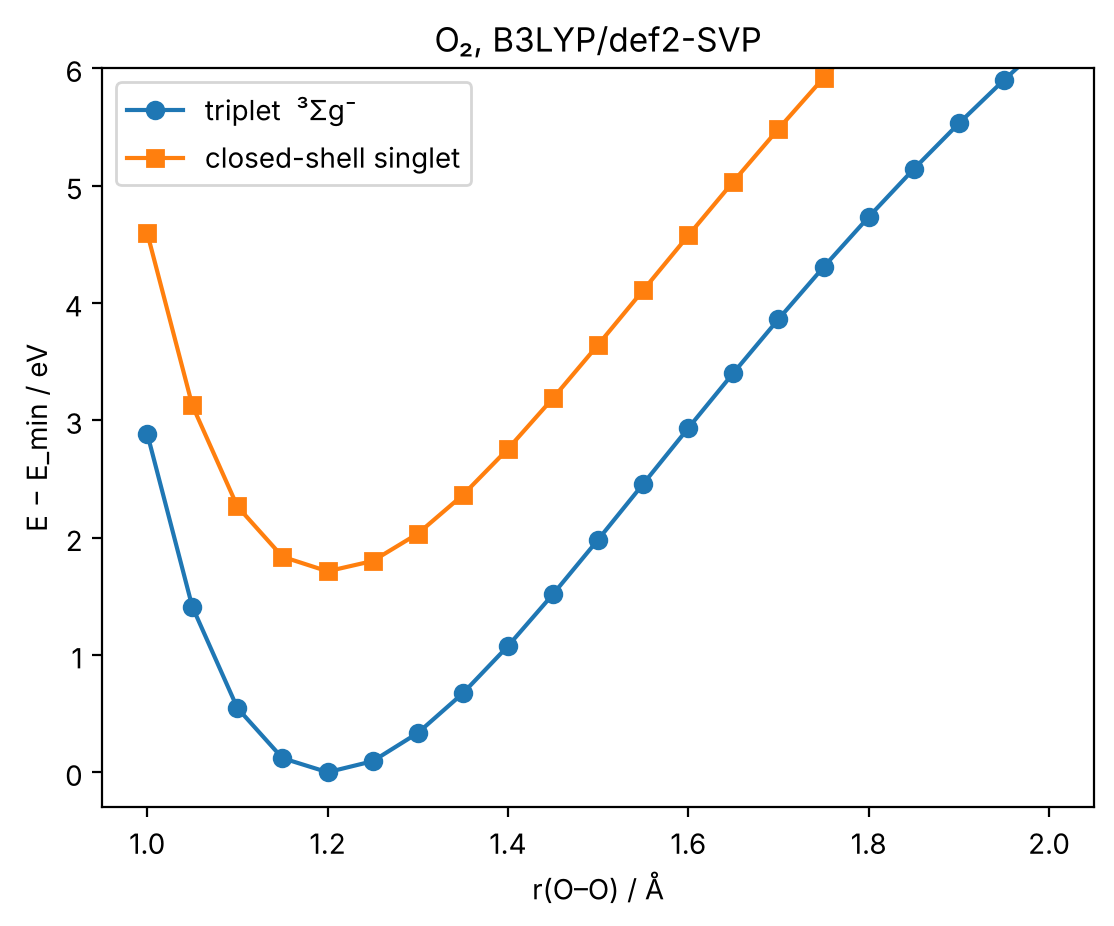

singlet - triplet at the triplet minimum: 1.71 eV


In [3]:
r_grid = np.linspace(1.00, 2.00, 21)
E_t = np.array([o2_energy(r, spin=2) for r in r_grid])
E_s = np.array([o2_energy(r, spin=0) for r in r_grid])
E_ref = E_t.min()

plt.plot(r_grid, E_t - E_ref, "o-", label="triplet  ³Σg⁻")
plt.plot(r_grid, E_s - E_ref, "s-", label="closed-shell singlet")
plt.xlabel("r(O–O) / Å"); plt.ylabel("E − E_min / eV"); plt.legend(); plt.ylim(-0.3, 6)
plt.title("O₂, B3LYP/def2-SVP"); plt.show()
print(f"singlet - triplet at the triplet minimum: {(E_s - E_t)[np.argmin(E_t)]:.2f} eV")

**Question 2.** Which spin state is the ground state? How does this explain why liquid O₂ is attracted to a magnet?
Draw the molecular-orbital diagram (σ, π, π*) and show where the last two electrons go.

*Your answer:*

<div style="background:#fff4e5;border-left:4px solid #e08a00;padding:8px 12px">

**Instructor notes**

The triplet lies about 1.7 eV below the closed-shell singlet. Two unpaired electrons give a net spin magnetic moment, which is paramagnetism.
MO diagram: (σ2s)²(σ*2s)²(σ2p)²(π2p)⁴(π*2p)². The two π* electrons occupy π*ₓ and π*ᵧ with parallel spins, giving bond order 2.
Caveat worth discussing: the real lowest singlet (a¹Δg, 0.98 eV) is an open-shell state that a single closed-shell determinant describes poorly, so the closed-shell gap overestimates it. The point stands: the triplet is the ground state.

</div>

## 3. Equilibrium bond length and harmonic frequency

Near its minimum, any smooth curve looks like a parabola:

$$E(r) \approx E(r_e) + \tfrac12 k (r - r_e)^2$$

A diatomic with force constant $k$ and **reduced mass** $\mu = m_1 m_2/(m_1+m_2)$ vibrates with

$$\omega = \sqrt{k/\mu}, \qquad \tilde\nu_e = \frac{\omega}{2\pi c}\ \ (\text{in cm}^{-1}).$$

**Exercise 3.**
(a) Compute the energy at 7 points within ±0.04 Å of the minimum of your triplet scan, and fit
a 4th-order polynomial (`np.polyfit`). Find $r_e$ and $k = E''(r_e)$ in eV/Å².
(b) Write `harmonic_wavenumber(k, m1, m2)` to convert $k$ (eV/Å²) and masses (amu) to cm⁻¹.
The constants are in `labkit`: $a\,[\text{Å/fs}^2] = F\,[\text{eV/Å}]/m\,[\text{amu}] \times$ `lk.ACC`,
and $c$ = `lk.C_CM_PER_FS` cm/fs.

In [4]:
def harmonic_wavenumber(k, m1, m2):
    """Harmonic wavenumber (cm^-1) for force constant k (eV/A^2) and atomic masses m1, m2 (amu)."""
    mu = m1 * m2 / (m1 + m2)
    omega = np.sqrt(k / mu * lk.ACC)          # rad/fs
    return omega / (2 * np.pi * lk.C_CM_PER_FS)

r0 = r_grid[np.argmin(E_t)]
r_fine = np.linspace(r0 - 0.04, r0 + 0.04, 7)
E_fine = np.array([o2_energy(r) for r in r_fine])
p = np.polyfit(r_fine - r0, E_fine, 4)
roots = np.roots(np.polyder(p))
x_e = roots[np.argmin(np.abs(roots))].real
r_e = r0 + x_e
k = np.polyval(np.polyder(p, 2), x_e)
m_O = lk.MASS["O"]
we = harmonic_wavenumber(k, m_O, m_O)
print(f"r_e = {r_e:.4f} A   (experiment 1.2075 A)")
print(f"k   = {k:.1f} eV/A^2")
print(f"harmonic wavenumber = {we:.0f} cm^-1   (experiment omega_e = 1580 cm^-1)")

r_e = 1.1999 A   (experiment 1.2075 A)
k   = 84.7 eV/A^2
harmonic wavenumber = 1697 cm^-1   (experiment omega_e = 1580 cm^-1)


In [5]:
# check: a 1H-35Cl bond with k = 32.0 eV/A^2 vibrates near 2990 cm^-1
assert abs(harmonic_wavenumber(32.0, lk.MASS["H"], lk.MASS["Cl"]) - 2990) < 15, "check your units"
print("harmonic_wavenumber passes the HCl check")

harmonic_wavenumber passes the HCl check


**Question 3.** B3LYP/def2-SVP gives a bond that is slightly too short and too stiff.
Name two approximations in this calculation that could cause this.

*Your answer:*

<div style="background:#fff4e5;border-left:4px solid #e08a00;padding:8px 12px">

**Instructor notes**

Expected (reference run): r_e = 1.200 Å, k ≈ 85 eV/Å², ν̃ ≈ 1700 cm⁻¹, D_e ≈ 5.5 eV. Sources of error: (1) the approximate functional (B3LYP overbinds multiple bonds slightly); (2) a small basis set (def2-SVP has no diffuse functions and a single polarization set); (3) experimental ωe is a harmonic constant derived from anharmonic levels, so comparing the harmonic value with the observed fundamental (1556 cm⁻¹) would mix in anharmonicity. Notebook 3 returns to that.

</div>

## 4. Bond dissociation energy

At long range the triplet curve goes to two O atoms, each in its ³P ground state.
The **dissociation energy** is $D_e = 2E(\text{O}) - E(\text{O}_2, r_e)$.

**Exercise 4.** Compute the energy of a single O atom (8 electrons, 2 unpaired: `spin=2`) and $D_e$.
Experiment: $D_e$ = 5.21 eV.

In [6]:
atom = gto.M(atom=[["O", (0, 0, 0)]], basis="def2-svp", spin=2, verbose=0)
mfa = dft.UKS(atom); mfa.xc = "b3lyp"
E_O = mfa.kernel() * lk.HARTREE_TO_EV
De = 2 * E_O - o2_energy(r_e)
print(f"D_e = {De:.2f} eV   (experiment 5.21 eV)")

D_e = 5.53 eV   (experiment 5.21 eV)


## 5. Why O₂ does not absorb infrared light

Light couples to a molecule through its **electric dipole moment** $\boldsymbol\mu$.
A vibration absorbs IR light only if the dipole **changes** during the vibration:

$$I_{\text{IR}} \propto \left|\frac{\partial \boldsymbol\mu}{\partial q}\right|^2.$$

**Exercise 5.** Use `mf.dip_moment(unit="Debye", verbose=0)` to compute the dipole of O₂ at three bond
lengths (1.1, 1.2 and 1.3 Å). What is $\partial\mu/\partial r$?

In [7]:
for r in (1.1, 1.2, 1.3):
    _, mf = o2_energy(r, return_mf=True)
    print(f"r = {r:.1f} A   dipole = {np.round(mf.dip_moment(unit='Debye', verbose=0), 6)} D")

r = 1.1 A   dipole = [0. 0. 0.] D


r = 1.2 A   dipole = [-0. -0. -0.] D


r = 1.3 A   dipole = [0. 0. 0.] D


**Question 5.** Explain from symmetry why the dipole of *every* homonuclear diatomic is zero at *every*
bond length. N₂ and O₂ make up 99 % of the atmosphere. What does your result mean for how the
atmosphere absorbs the infrared light emitted by the Earth's surface?

*Your answer:*

<div style="background:#fff4e5;border-left:4px solid #e08a00;padding:8px 12px">

**Instructor notes**

The molecule has a centre of inversion at every bond length; the dipole is a vector, so inversion sends μ to −μ, and it must be zero. dμ/dr = 0, so the O₂ stretch is IR-inactive (it is Raman-active). N₂ and O₂ are transparent in the thermal IR; the greenhouse effect comes from the minor species with changing dipoles (H₂O, CO₂, CH₄, N₂O, O₃). Notebook 4 shows which CO₂ vibrations do this. (O₂ has a very weak magnetic-dipole and collision-induced absorption, far too weak to matter here.)

</div>

## Summary

| quantity | B3LYP/def2-SVP | experiment |
|---|---|---|
| ground state | your result | ³Σg⁻ (triplet) |
| $r_e$ / Å | your result | 1.2075 |
| $\tilde\nu_e$ / cm⁻¹ | your result | 1580 |
| $D_e$ / eV | your result | 5.21 |

**Before you move on:** save your functions. You will write the same kind of function for CO in
Notebook 2. Next you will ask *how good* the energies are, and how to improve them systematically.